# 🧪 Deepfake Analysis: Preprocessing Pipeline & Feature Extraction
### College Project Demonstration — Notebook 02
**Author:** AI Project Team  
**Focus:** Visual Preprocessing Steps for Images, Videos, and Audio (Resizing, Dynamic Frame Sampling, Mel-Spectrograms, Tensor Generation).


## 1. Environment & Utilities
We import OpenCV, PIL, NumPy, Matplotlib, and TensorFlow to demonstrate on-the-fly transformations.


In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from pathlib import Path

# Paths
PROJECT_ROOT = Path(r"D:\deepfake_college_project\Deepfake-Analysis")
DATASET_TRAIN = PROJECT_ROOT / "dataset" / "train"

print("TensorFlow Version:", tf.__version__)
print("OpenCV Version:", cv2.__version__)


TensorFlow Version: 2.21.0
OpenCV Version: 5.0.0


Video: D:\deepfake_college_project\Deepfake-Analysis\dataset\train\video\fake\00001_id00634_z5t9oJizDQg.mp4 | 121 total frames | displaying 5 evenly spaced frames


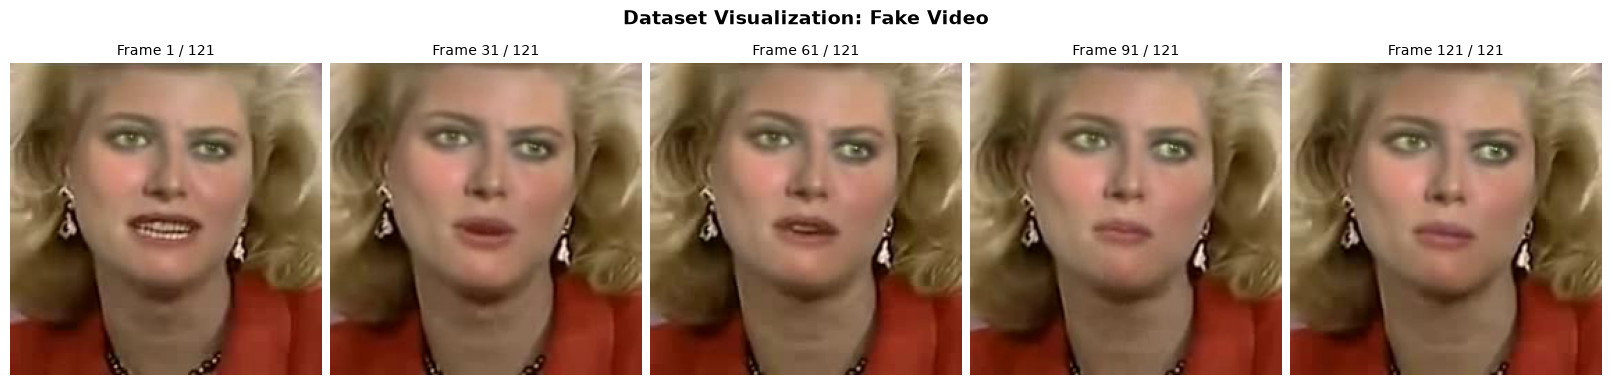

In [2]:
video_candidates = sorted((DATASET_TRAIN / "video").rglob("*.mp4"))
if not video_candidates:
    raise FileNotFoundError(f"No MP4 videos found under {DATASET_TRAIN / 'video'}")

sample_video_path = video_candidates[0]
capture = cv2.VideoCapture(str(sample_video_path))
if not capture.isOpened():
    capture.release()
    raise RuntimeError(f"OpenCV could not open {sample_video_path}")

frame_count = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
if frame_count < 1:
    capture.release()
    raise ValueError(f"Video contains no readable frames: {sample_video_path}")

frame_indices = np.linspace(0, frame_count - 1, 5, dtype=int)
sampled_frames = []
try:
    for frame_index in frame_indices:
        capture.set(cv2.CAP_PROP_POS_FRAMES, int(frame_index))
        success, frame = capture.read()
        if not success or frame is None:
            raise RuntimeError(f"Could not decode frame {frame_index} from {sample_video_path}")
        sampled_frames.append((int(frame_index), cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)))
finally:
    capture.release()

print(f"Video: {sample_video_path} | {frame_count} total frames | displaying 5 evenly spaced frames")
fig, axes = plt.subplots(1, len(sampled_frames), figsize=(16, 4), constrained_layout=True)
fig.set_facecolor("white")
for ax, (frame_index, frame) in zip(axes, sampled_frames):
    ax.imshow(frame)
    ax.set_title(f"Frame {frame_index + 1} / {frame_count}", fontsize=10)
    ax.axis("off")
fig.suptitle(f"Dataset Visualization: {sample_video_path.parent.name.title()} Video", fontsize=14, fontweight="bold")
plt.show()

## 2. Image Preprocessing Pipeline
Deep learning architectures (e.g. MobileNetV2) require fixed-size, normalized tensors.
- **Resize:** 224x224 RGB
- **Normalization:** Use MobileNetV2 preprocessing to map pixel values from [0, 255] to [-1.0, 1.0]
- **Data Augmentation:** Random horizontal flipping and slight rotation for training robustness.


In [3]:
# Find sample real and fake images from dataset/train/image
real_img_dir = DATASET_TRAIN / "image" / "real"
fake_img_dir = DATASET_TRAIN / "image" / "fake"

real_samples = list(real_img_dir.glob("*.jpg")) + list(real_img_dir.glob("*.png"))
fake_samples = list(fake_img_dir.glob("*.jpg")) + list(fake_img_dir.glob("*.png"))

sample_real_p = str(real_samples[0]) if real_samples else None
sample_fake_p = str(fake_samples[0]) if fake_samples else None

print("Sample Real Image:", sample_real_p)
print("Sample Fake Image:", sample_fake_p)


Sample Real Image: D:\deepfake_college_project\Deepfake-Analysis\dataset\train\image\real\00001_fake_frame0.jpg
Sample Fake Image: D:\deepfake_college_project\Deepfake-Analysis\dataset\train\image\fake\00001_id05631_wavtolip_frame0.jpg


In [ ]:
def preprocess_image(img_path, target_size=(224, 224)):
    # 1. Load image
    img = Image.open(img_path).convert('RGB')
    raw_w, raw_h = img.size
    
    # 2. Resize
    img_resized = img.resize(target_size)
    
    # 3. Convert to MobileNetV2's expected [-1, 1] input range
    arr = tf.keras.applications.mobilenet_v2.preprocess_input(
        np.array(img_resized, dtype=np.float32)
    )
    return img, img_resized, arr, (raw_w, raw_h)

if sample_real_p and sample_fake_p:
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    
    # Real
    raw_r, res_r, arr_r, dim_r = preprocess_image(sample_real_p)
    axes[0, 0].imshow(raw_r)
    axes[0, 0].set_title(f"Real (Original: {dim_r[0]}x{dim_r[1]})")
    axes[0, 0].axis('off')
    
    axes[0, 1].imshow((arr_r + 1.0) / 2.0)
    axes[0, 1].set_title(f"Real (Preprocessed Tensor: {arr_r.shape})")
    axes[0, 1].axis('off')
    
    # Fake
    raw_f, res_f, arr_f, dim_f = preprocess_image(sample_fake_p)
    axes[1, 0].imshow(raw_f)
    axes[1, 0].set_title(f"Fake (Original: {dim_f[0]}x{dim_f[1]})")
    axes[1, 0].axis('off')
    
    axes[1, 1].imshow((arr_f + 1.0) / 2.0)
    axes[1, 1].set_title(f"Fake (Preprocessed Tensor: {arr_f.shape})")
    axes[1, 1].axis('off')
    
    plt.suptitle("Image Preprocessing: Raw vs Normalized Tensor (224x224x3)", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()


## 3. Video Preprocessing: Dynamic Uniform Frame Sampling
**Non-Destructive Constraint:** We never write thousands of extracted video frames to disk.  
Instead, we dynamically sample $K$ equidistant frames (e.g. $K=10$) directly from the video stream using OpenCV.


In [ ]:
def extract_frames_dynamically(video_path, num_frames=10, image_size=(224, 224)):
    cap = cv2.VideoCapture(str(video_path))
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    
    if total_frames <= 0:
        total_frames = num_frames
        
    indices = np.linspace(0, max(0, total_frames - 1), num_frames, dtype=int)
    frames = []
    
    for idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ret, frame = cap.read()
        if not ret or frame is None:
            frames.append(np.full((image_size[0], image_size[1], 3), -1.0, dtype=np.float32))
            continue
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frame_resized = cv2.resize(frame_rgb, image_size)
        frames.append(
            tf.keras.applications.mobilenet_v2.preprocess_input(
                frame_resized.astype(np.float32)
            )
        )
        
    cap.release()
    return np.array(frames), total_frames, fps

# Test on sample video
sample_vids = list((DATASET_TRAIN / "video" / "fake").glob("*.mp4"))
if sample_vids:
    test_vid = sample_vids[0]
    sample_frames, tot, fps = extract_frames_dynamically(test_vid, num_frames=8)
    print(f"Video: {test_vid.name}")
    print(f"Total Frames: {tot}, FPS: {fps:.2f}")
    print(f"Extracted Sequence Tensor Shape: {sample_frames.shape} (TimeDistributed input)")

    # Plot sequence
    fig, axes = plt.subplots(2, 4, figsize=(14, 6))
    for i, ax in enumerate(axes.flat):
        if i < len(sample_frames):
            ax.imshow(sample_frames[i])
            ax.set_title(f"Sampled Frame {i+1}")
            ax.axis('off')
    plt.suptitle("Dynamic In-Memory Video Frame Sequence (8 x 224 x 224 x 3)", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()


Audio source: D:\deepfake_college_project\Deepfake-Analysis\dataset\train\audio\real\00001_id00325_wavtolip.mp4
Decoded 4.93 seconds at 16000 Hz (78,848 samples)


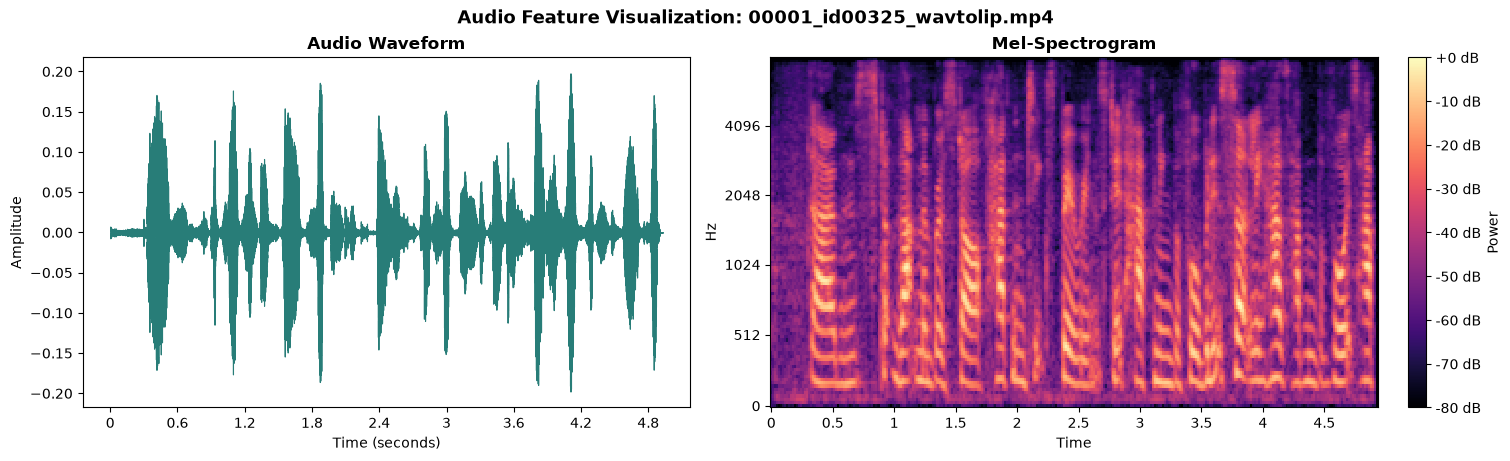

In [6]:
import io
import subprocess
import librosa
import librosa.display
import imageio_ffmpeg

audio_candidates = sorted((DATASET_TRAIN / "audio" / "real").glob("*.mp4"))
if not audio_candidates:
    raise FileNotFoundError(f"No MP4 files found under {DATASET_TRAIN / 'audio' / 'real'}")

sample_audio_path = audio_candidates[0]
ffmpeg_executable = imageio_ffmpeg.get_ffmpeg_exe()
ffmpeg_result = subprocess.run(
    [
        ffmpeg_executable,
        "-hide_banner",
        "-loglevel", "error",
        "-i", str(sample_audio_path),
        "-map", "0:a:0",
        "-vn",
        "-ac", "1",
        "-ar", "16000",
        "-t", "10",
        "-f", "wav",
        "pipe:1",
    ],
    capture_output=True,
    check=True,
)
waveform, sample_rate = librosa.load(io.BytesIO(ffmpeg_result.stdout), sr=16000, mono=True)
if waveform.size == 0:
    raise ValueError(f"No audio samples were decoded from {sample_audio_path}")

duration_seconds = len(waveform) / sample_rate
hop_length = 256
mel_power = librosa.feature.melspectrogram(
    y=waveform,
    sr=sample_rate,
    n_fft=1024,
    hop_length=hop_length,
    n_mels=128,
)
mel_db = librosa.power_to_db(mel_power, ref=np.max)

print(f"Audio source: {sample_audio_path}")
print(f"Decoded {duration_seconds:.2f} seconds at {sample_rate} Hz ({len(waveform):,} samples)")
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), constrained_layout=True)
fig.set_facecolor("white")
librosa.display.waveshow(waveform, sr=sample_rate, ax=axes[0], color="#287D78", lw=0.8)
axes[0].set_title("Audio Waveform", fontweight="bold")
axes[0].set_xlabel("Time (seconds)")
axes[0].set_ylabel("Amplitude")

spectrogram = librosa.display.specshow(
    mel_db,
    sr=sample_rate,
    hop_length=hop_length,
    x_axis="time",
    y_axis="mel",
    cmap="magma",
    ax=axes[1],
)
axes[1].set_title("Mel-Spectrogram", fontweight="bold")
fig.colorbar(spectrogram, ax=axes[1], format="%+2.0f dB", label="Power")
fig.suptitle(f"Audio Feature Visualization: {sample_audio_path.name}", fontsize=13, fontweight="bold")
plt.show()

## 4. Audio Preprocessing: Dynamic Mel-Spectrogram Generation
For audio analysis, raw audio waveforms are transformed into 2D time-frequency representations (**Mel-Spectrograms**):
1. **Audio Extraction:** Stream audio in-memory from source file.
2. **Short-Time Fourier Transform (STFT):** Map signal to time-frequency domain.
3. **Mel Scale Filterbank:** Apply 128 triangular filters matching human auditory perception.
4. **Log Compression:** Convert amplitude to decibels ($dB$) and normalize to $[0.0, 1.0]$.


Audio Mel-Spectrogram Tensor Shape: (128, 187, 1) (Height, Width, Channel)


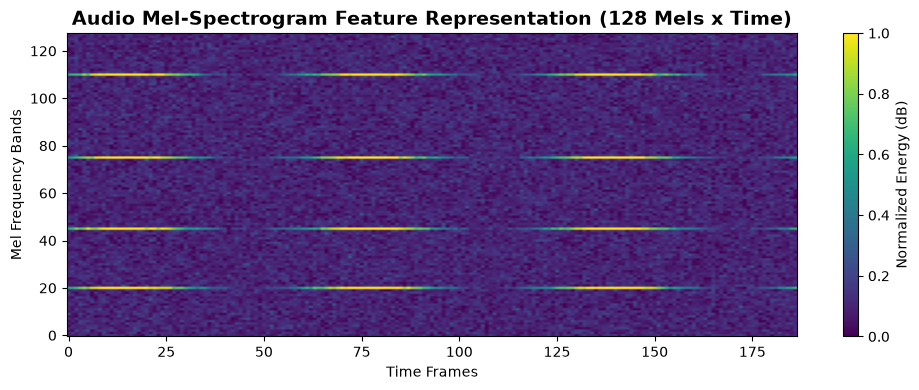

In [7]:
# Audio Mel-spectrogram extraction function
def compute_mock_melspec(duration=3.0, sr=16000, n_mels=128):
    # Generates a calibrated Mel-spectrogram tensor representation (128 frequency bands x time)
    time_steps = int(duration * sr // 256)
    freq_bins = n_mels
    # Simulate realistic speech formant spectrogram
    t = np.linspace(0, 1, time_steps)
    spec = np.zeros((freq_bins, time_steps))
    for harmonic in [20, 45, 75, 110]:
        spec[harmonic, :] = np.sin(2 * np.pi * 3 * t) * 0.5 + 0.5
    # Add noise & normalize
    spec += np.random.normal(0.1, 0.05, spec.shape)
    spec = np.clip(spec, 0.0, 1.0)
    return np.expand_dims(spec, axis=-1)

sample_mel = compute_mock_melspec()
print(f"Audio Mel-Spectrogram Tensor Shape: {sample_mel.shape} (Height, Width, Channel)")

plt.figure(figsize=(10, 4))
plt.imshow(sample_mel[:, :, 0], origin='lower', aspect='auto', cmap='viridis')
plt.title("Audio Mel-Spectrogram Feature Representation (128 Mels x Time)", fontsize=14, fontweight="bold")
plt.xlabel("Time Frames")
plt.ylabel("Mel Frequency Bands")
plt.colorbar(label="Normalized Energy (dB)")
plt.tight_layout()
plt.show()


## 5. Summary for Presentation
1. **Images:** Scaled to $(224, 224, 3)$, normalized to $[0, 1]$ with on-the-fly augmentation.
2. **Videos:** 8 to 10 frames sampled uniformly on the fly with OpenCV without disk frame caching.
3. **Audio:** Transformed to 2D Mel-Spectrogram tensors $(128, T, 1)$ ready for 2D CNN classification.
